In [1]:
import numpy as np
import os
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
def parallel_tempering(matrix: np.ndarray, beta0: float, beta1: float,tau:int = 20,sweeps:int = 1000,  init_state: np.ndarray = None):
    N = matrix.shape[0]
    print(N)
    step = (beta1 - beta0) / (sweeps - 1)
    beta = beta0
    energy = lambda state: ( state.transpose() @ matrix @ state ) / 2
    if init_state is None:
        state = np.random.choice([-1,1], N, replace=True)
    else:
        state = init_state
    ene = energy(state)
    ene_vals = []
    ene_vals.append(ene)
    best_ene = ene
    best_state = state
    for i in range(sweeps):
        for s in range(N):
            rng = np.random.sample()
            state[s] = -1 * state[s]
            trial_ene = energy(state)
            if np.log(rng) < (beta * (ene - trial_ene)):
                ene =  trial_ene
                ene_vals.append(ene)
                if ene < best_ene:
                    best_ene = ene
                    best_state = state
            else:
                state[s] = -1 * state[s]
        beta += step
    return best_ene, best_state, ene_vals

In [67]:
def gset_to_array(path: str):
    with open(path) as gfile:
        nodes, edges = [int(i) for i in gfile.readline().strip().split()]
        arr = np.zeros((nodes, nodes))
        for line in gfile.readlines():
            args = line.strip().split()
            if len(args) < 2:
                continue
            if len(args) == 2:
                arr[int(args[0]), int(args[1])] = 1
                arr[int(args[1]), int(args[0])] = 1
                continue

            arr[int(args[0]), int(args[1])] = float(args[2])
            arr[int(args[1]), int(args[0])] = float(args[2])
    return arr

In [70]:
J = gset_to_array(os.environ['GSET'] + '/sk/sk_normal_n_200_0.gset')

In [59]:
J = np.random.standard_normal(size=200*200).reshape((200,200))

In [71]:
ene, state, vals = parallel_tempering(-J, 0.05, 2)

200


1081.6601840158783

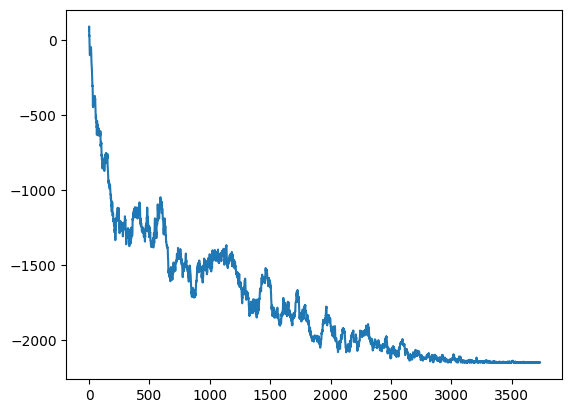

In [77]:
sns.lineplot(vals)
cut = (-ene + J.sum()) / 2
cut

1081.6601840158783

In [66]:
ene

-1533.4875927464097

In [48]:
J.sum()

11.987652830127235